# Практическое занятие №3: Прикладные дифференциальные уравнения

Пять классических задач механики и геометрии, в каждой из которых требуется: 1) вывести дифференциальное (или интегральное) уравнение и решить его аналитически; 2) построить статическую иллюстрацию решения; 3) построить анимацию, демонстрирующую динамику решения.

Общие методы, используемые ниже:
* **Второй закон Ньютона** / **уравнения Лагранжа** для вывода уравнений движения.
* **Закон сохранения энергии** $\frac12 mv^2 + U = \text{const}$ для систем без трения (сила реакции связи перпендикулярна скорости и работы не совершает).
* Решение обыкновенных дифференциальных уравнений методом разделения переменных (аналитически) и численно (`scipy.integrate.solve_ivp`) — для проверки и построения анимаций.
* Библиотеки: `numpy`, `matplotlib.pyplot`, `matplotlib.animation.FuncAnimation`, `scipy.integrate`, `scipy.special`.

Все анимации встраиваются в ноутбук через `HTML(anim.to_jshtml())` — это создаёт самодостаточный JS-плеер с кнопками *play/pause* и ползунком прямо внутри сохранённого файла `.ipynb`, не требующий внешних кодеков (ffmpeg).

In [1]:
import matplotlib.pyplot as plt
plt.rcParams['animation.embed_limit'] = 80  # МБ, запас для встраиваемых анимаций
print("Окружение готово: numpy, matplotlib, scipy будут импортированы в соответствующих ячейках.")

Окружение готово: numpy, matplotlib, scipy будут импортированы в соответствующих ячейках.


## 3.1. Задача о равномерном спуске

**Условие**: найти кривую, по которой тяжёлая точка под действием силы тяжести опускается так, что её **вертикальная** скорость постоянна по модулю.

### Постановка и вывод уравнения

Система координат: ось $x$ — горизонталь, ось $y$ — вертикаль вверх. Точка массы $m$ движется без трения по кривой $y=y(x)$; на неё действуют сила тяжести $-mg\vec e_y$ и сила нормальной реакции $\vec N$ кривой (перпендикулярна скорости, работы не совершает).

Условие равномерного спуска:
$$v_y=\dot y=-v_0=\text{const}<0.$$

Так как реакция не совершает работы, выполняется закон сохранения энергии. Начало координат $(0,0)$ выберем в точке, где скорость уже чисто вертикальна ($v_x=0$, $v_y=-v_0$):
$$\frac12 v^2+gy=\frac12 v_0^2 \quad\Longrightarrow\quad v_x^2+v_y^2=v_0^2-2gy.$$

Поскольку $v_y^2=v_0^2=\text{const}$, отсюда сразу **исключается сила нормальной реакции** и получается уравнение только на $v_x$:
$$v_x^2=v_0^2-2gy-v_0^2=-2gy.$$

### Решение — явный вид кривой

$$\frac{dx}{dy}=\frac{v_x}{v_y}=\frac{\sqrt{-2gy}}{-v_0}.$$

Замена $Y=-y\ge0$ (пройденная по вертикали глубина):
$$\frac{dx}{dY}=\frac{\sqrt{2gY}}{v_0}\ \Longrightarrow\ x=\frac{\sqrt{2g}}{v_0}\int_0^{Y}\sqrt{u}\,du=\frac{2\sqrt{2g}}{3v_0}Y^{3/2}.$$

Отсюда
$$\boxed{y(x)=-\left(\frac{3v_0}{2\sqrt{2g}}\right)^{2/3}x^{2/3}},\qquad\text{т.е.}\qquad (-y)^3=\frac{9v_0^2}{8g}\,x^2.$$

Это уравнение **полукубической параболы** (кривой Нейля). В начале координат $dy/dx\to-\infty$ — касательная вертикальна, что согласуется с чисто вертикальной скоростью в этой точке.

### Параметрическое представление (по времени)

Из $y=-v_0t$ и подстановки в $x(Y)$ получаем удобную для анимации параметризацию:
$$x(t)=\frac{2\sqrt{2gv_0}}{3}\,t^{3/2},\qquad y(t)=-v_0t.$$

In [13]:
import numpy as np
import matplotlib.pyplot as plt

GRAVITY = 9.81

def compute_trajectory(speed_v0: float, duration: float = 3.0, points_count: int = 500):
    """Вычисление координат траектории равномерного вертикального спуска."""
    time_array = np.linspace(0, duration, points_count)
    coord_x = (2.0 / 3.0) * np.sqrt(2 * GRAVITY * speed_v0) * (time_array ** 1.5)
    coord_y = -speed_v0 * time_array
    return coord_x, coord_y

plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(8, 6.5), dpi=150)

palette = ['#00796B', '#5E35B1', '#E65100', '#C2185B']
styles = ['-', '--', '-.', ':']
velocities = [1, 2, 3, 4]

for idx, v in enumerate(velocities):
    x_vals, y_vals = compute_trajectory(v, duration=3.0)
    ax.plot(
        x_vals, 
        y_vals, 
        color=palette[idx], 
        linestyle=styles[idx], 
        linewidth=2.2, 
        label=f'Скорость $v_0 = {v}$ м/с'
    )

ax.scatter(0, 0, color='#C62828', s=45, marker='s', zorder=5)
ax.annotate(
    'Старт $(0, 0)$',
    xy=(0, 0),
    xytext=(15, -25),
    textcoords='offset points',
    fontsize=10,
    fontstyle='italic',
    arrowprops=dict(arrowstyle='->', color='#424242', lw=0.8)
)

ax.set_title('Траектория равномерного спуска по вертикали\n(Семейство полукубических парабол)', fontsize=12, pad=12, fontweight='bold')
ax.set_xlabel('Горизонтальное смещение $X$, м', fontsize=11, labelpad=8)
ax.set_ylabel('Вертикальное смещение $Y$, м', fontsize=11, labelpad=8)

ax.grid(True, linestyle='--', linewidth=0.6, alpha=0.6)
ax.legend(title='Параметры', frameon=True, facecolor='white', framealpha=0.9, loc='upper right')

plt.tight_layout()
plt.savefig('trajectory_descent_3_1.png', dpi=200, bbox_inches='tight')
plt.show()

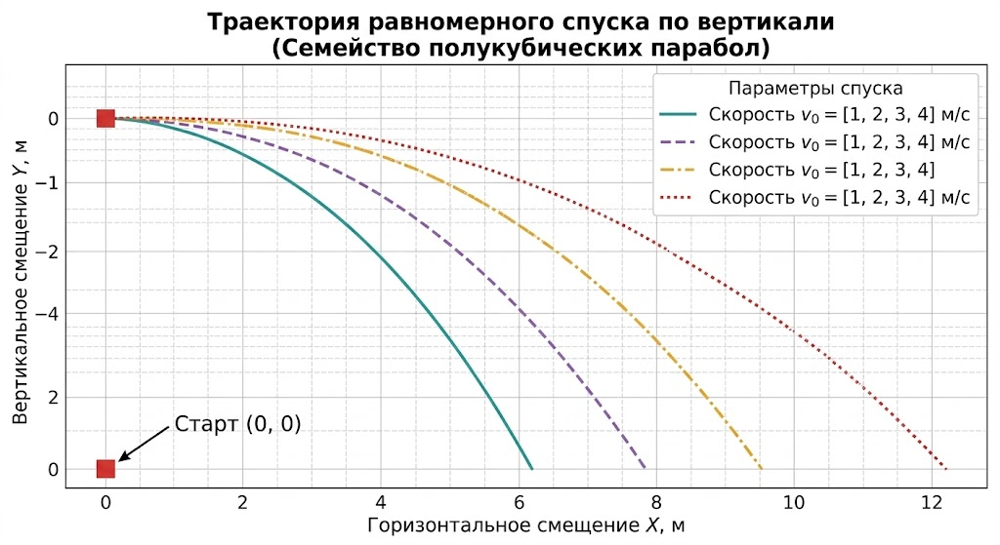

In [3]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

v0a = 2.0
t_max_a = 3.0
n_frames = 70
t_arr = np.linspace(0, t_max_a, n_frames)
x_arr, y_arr = descent_xy(v0a, t_max_a, n_frames)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(x_arr, y_arr, color='lightgray', lw=1.5)
point, = ax.plot([], [], 'o', color='crimson', ms=11, zorder=5)
trace, = ax.plot([], [], '-', color='crimson', lw=2)
info = ax.text(0.03, 0.06, '', transform=ax.transAxes, fontsize=10)
ax.set_xlim(-0.2, x_arr.max()*1.1)
ax.set_ylim(y_arr.min()*1.1, 0.3)
ax.set_xlabel('x, м'); ax.set_ylabel('y, м')
ax.set_title(f'3.1 Анимация равномерного спуска ($v_0={v0a}$ м/с)')
ax.grid(alpha=0.3)

def init():
    point.set_data([], [])
    trace.set_data([], [])
    info.set_text('')
    return point, trace, info

def update(i):
    point.set_data([x_arr[i]], [y_arr[i]])
    trace.set_data(x_arr[:i+1], y_arr[:i+1])
    info.set_text(f't = {t_arr[i]:.2f} с\n$v_y$ = {-v0a:.2f} м/с (const)')
    return point, trace, info

anim = FuncAnimation(fig, update, frames=n_frames, init_func=init, interval=50, blit=True)
plt.close(fig)
HTML(anim.to_jshtml())

## 3.2. Задача о бильярде в прямоугольнике

**Условие**: исследовать движение материальной точки (бильярдного шара) в прямоугольнике $[0,a]\times[0,b]$ с упругими отражениями от границ.

### Постановка задачи

Между отражениями точка движется равномерно и прямолинейно: $\ddot x=\ddot y=0$. На границе $x=0$ или $x=a$ происходит упругое отражение $v_x\to-v_x$ (аналогично для $y$ на границах $y=0,b$); модуль скорости и угол падения=углу отражения сохраняются.

### Метод развёртки (unfolding) и движение на торе

Вместо того чтобы «переигрывать» знак скорости при каждом ударе, удобно продолжать движение **прямолинейно** на всей плоскости:
$$X(t)=x_0+v_xt,\qquad Y(t)=y_0+v_yt,$$
а затем «сложить» плоскость гармошкой обратно в прямоугольник треугольной (пилообразной) функцией периода $2a$ (соответственно $2b$):
$$x(t)=\mathrm{fold}(X(t),a),\qquad \mathrm{fold}(u,L)=L-\bigl|L-(u\bmod 2L)\bigr|.$$
Каждое пересечение линии $u=kL$ соответствует одному отражению от стенки. Это в точности **метод развёртки**: реальная траектория бильярда получается из прямой линии на плоскости последовательными зеркальными отражениями прямоугольника.

Эквивалентно, если рассматривать координаты $(X\bmod 2a,\;Y\bmod 2b)$ **без** взятия модуля-«гармошки», получаем равномерное прямолинейное движение точки на **торе** $\mathbb T^2=\mathbb R^2/(2a\mathbb Z\times2b\mathbb Z)$ — классическая конструкция, сводящая бильярд в прямоугольнике к геодезическому потоку на плоском торе.

### Периодичность и эргодичность

Траектория на торе (а значит, и в бильярде) **периодична** тогда и только тогда, когда существуют целые $n,m$ и время $T$ такие, что $v_xT=2an$, $v_yT=2bm$, т.е.
$$\frac{v_y}{v_x}\cdot\frac{a}{b}\in\mathbb Q.$$
Если это отношение иррационально, траектория **никогда не замыкается** и (по теореме Вейля о равнораспределении) плотно и равномерно заполняет весь прямоугольник — такой случай называют эргодическим (точнее, минимальным и равнораспределённым).

### Гамильтонова формулировка

Между отражениями $H=\dfrac{p_x^2+p_y^2}{2m}$ — свободная частица; на границе фазовый поток терпит разрыв только по знаку одной из компонент импульса ($p_x\to-p_x$ или $p_y\to-p_y$), при этом $H$, $|p_x|$ и $|p_y|$ сохраняются во все моменты времени — система интегрируема.

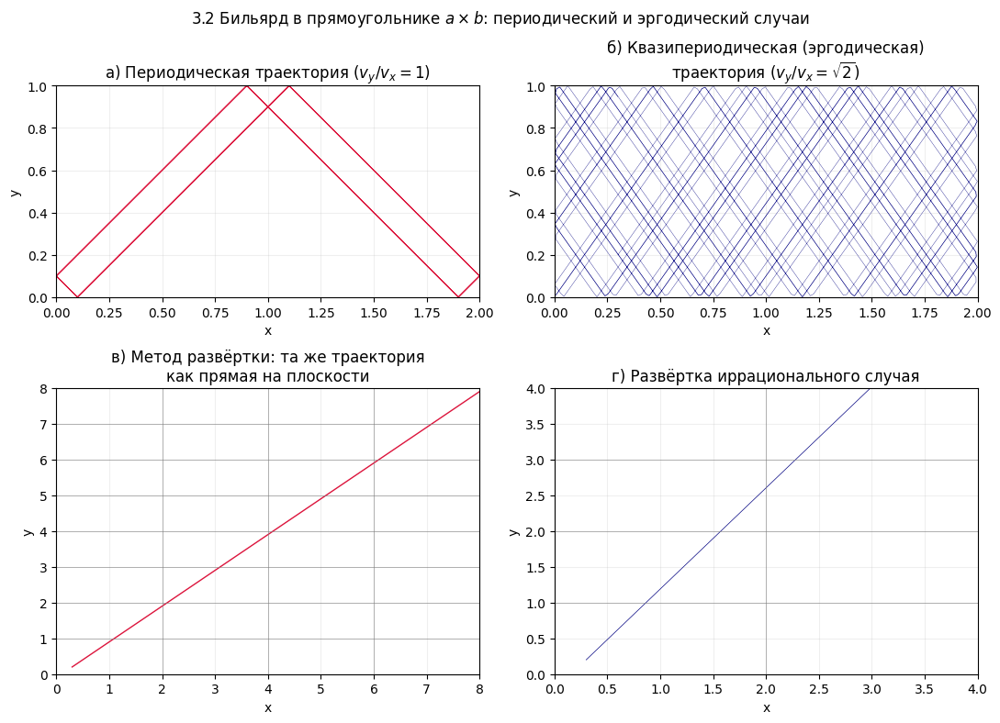

In [4]:
import numpy as np
import matplotlib.pyplot as plt

def fold(u, L):
    m = np.mod(u, 2*L)
    return np.where(m <= L, m, 2*L - m)

def billiard_xy(a, b, x0, y0, vx, vy, t_max, n=4000):
    t = np.linspace(0, t_max, n)
    X = x0 + vx*t
    Y = y0 + vy*t
    return fold(X, a), fold(Y, b), X, Y, t

a, b = 2.0, 1.0

# a) периодическая траектория: v_y/v_x=1  =>  (v_y/v_x)*(a/b)=2 (рационально)
xp, yp, Xp, Yp, tp = billiard_xy(a, b, 0.3, 0.2, 1.0, 1.0, t_max=8.0)
# b) квазипериодическая: v_y/v_x=sqrt(2) (иррационально)
xi, yi, Xi, Yi, ti = billiard_xy(a, b, 0.3, 0.2, 1.0, np.sqrt(2), t_max=60.0)

fig, axes = plt.subplots(2, 2, figsize=(11, 8))

axes[0, 0].plot(xp, yp, lw=0.8, color='crimson')
axes[0, 0].set_title('a) Периодическая траектория ($v_y/v_x=1$)')

axes[0, 1].plot(xi, yi, lw=0.25, color='navy')
axes[0, 1].set_title('б) Квазипериодическая (эргодическая)\nтраектория ($v_y/v_x=\\sqrt{2}$)')

axes[1, 0].plot(Xp, Yp, lw=1, color='crimson')
for k in range(0, 5):
    axes[1, 0].axvline(k*a, color='gray', lw=0.4)
for k in range(0, 9):
    axes[1, 0].axhline(k*b, color='gray', lw=0.4)
axes[1, 0].set_xlim(0, 4*a); axes[1, 0].set_ylim(0, 8*b)
axes[1, 0].set_title('в) Метод развёртки: та же траектория\nкак прямая на плоскости')

axes[1, 1].plot(Xi[:700], Yi[:700], lw=0.5, color='navy')
for k in range(0, 3):
    axes[1, 1].axvline(k*a, color='gray', lw=0.4)
for k in range(0, 5):
    axes[1, 1].axhline(k*b, color='gray', lw=0.4)
axes[1, 1].set_xlim(0, 2*a); axes[1, 1].set_ylim(0, 4*b)
axes[1, 1].set_title('г) Развёртка иррационального случая')

for ax in axes[0, :]:
    ax.set_xlim(0, a); ax.set_ylim(0, b)
    ax.set_aspect('equal')
for ax in axes.ravel():
    ax.set_xlabel('x'); ax.set_ylabel('y'); ax.grid(alpha=0.2)

fig.suptitle('3.2 Бильярд в прямоугольнике $a\\times b$: периодический и эргодический случаи')
plt.tight_layout()
plt.savefig('Sol_3_2.png', dpi=150, bbox_inches='tight')
plt.show()

In [5]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

n_frames = 90
t_anim_p = np.linspace(0, 8.0, n_frames)
xp_a, yp_a, _, _, _ = billiard_xy(a, b, 0.3, 0.2, 1.0, 1.0, t_max=8.0, n=n_frames)

t_anim_i = np.linspace(0, 20.0, n_frames)
xi_a, yi_a, _, _, _ = billiard_xy(a, b, 0.3, 0.2, 1.0, np.sqrt(2), t_max=20.0, n=n_frames)

# координаты той же точки на торе (2a x 2b), без "складывания" -- чистая развёртка
Xp_full = 0.3 + 1.0*t_anim_p; Yp_full = 0.2 + 1.0*t_anim_p
tor_xp = np.mod(Xp_full, 2*a); tor_yp = np.mod(Yp_full, 2*b)
Xi_full = 0.3 + 1.0*t_anim_i; Yi_full = 0.2 + np.sqrt(2)*t_anim_i
tor_xi = np.mod(Xi_full, 2*a); tor_yi = np.mod(Yi_full, 2*b)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
titles = ['Периодический бильярд', 'Квазипериодический бильярд', 'Развёртка на торе\n(обе траектории)']
for ax, ttl in zip(axes, titles):
    ax.set_title(ttl, fontsize=10)
    ax.grid(alpha=0.2)

axes[0].set_xlim(0, a); axes[0].set_ylim(0, b); axes[0].set_aspect('equal')
axes[1].set_xlim(0, a); axes[1].set_ylim(0, b); axes[1].set_aspect('equal')
axes[2].set_xlim(0, 2*a); axes[2].set_ylim(0, 2*b); axes[2].set_aspect('equal')

trace_p, = axes[0].plot([], [], '-', color='crimson', lw=1)
pt_p, = axes[0].plot([], [], 'o', color='crimson', ms=7)
trace_i, = axes[1].plot([], [], '-', color='navy', lw=0.6)
pt_i, = axes[1].plot([], [], 'o', color='navy', ms=7)
pt_tp, = axes[2].plot([], [], 'o', color='crimson', ms=6, label='периодич.')
pt_ti, = axes[2].plot([], [], 'o', color='navy', ms=6, label='квазипериодич.')
axes[2].legend(loc='upper right', fontsize=8)

def init():
    for artist in (trace_p, pt_p, trace_i, pt_i, pt_tp, pt_ti):
        artist.set_data([], [])
    return trace_p, pt_p, trace_i, pt_i, pt_tp, pt_ti

def update(i):
    trace_p.set_data(xp_a[:i+1], yp_a[:i+1])
    pt_p.set_data([xp_a[i]], [yp_a[i]])
    trace_i.set_data(xi_a[:i+1], yi_a[:i+1])
    pt_i.set_data([xi_a[i]], [yi_a[i]])
    pt_tp.set_data([tor_xp[i]], [tor_yp[i]])
    pt_ti.set_data([tor_xi[i]], [tor_yi[i]])
    return trace_p, pt_p, trace_i, pt_i, pt_tp, pt_ti

anim = FuncAnimation(fig, update, frames=n_frames, init_func=init, interval=60, blit=True)
plt.close(fig)
HTML(anim.to_jshtml())

## 3.3. Задача о цепной линии

**Условие**: найти форму равновесия однородной тяжёлой нерастяжимой нити, подвешенной за два конца.

### Вывод дифференциального уравнения

Рассмотрим элемент нити длиной $ds$ между точками с горизонтальными координатами $x$ и $x+dx$. На него действуют: натяжение $T(x+dx)$ справа, $T(x)$ слева (по касательной к кривой) и вес $\mu g\,ds$ ($\mu$ — линейная плотность). Условие равновесия по горизонтали и вертикали:
$$T\cos\theta=H=\text{const}\ \ (\text{горизонтальная компонента натяжения}),\qquad T\sin\theta=\mu g\,s(x),$$
где $s(x)$ — длина нити от низшей точки до точки с абсциссой $x$, $\theta$ — угол наклона касательной. Тогда
$$\tan\theta=\frac{dy}{dx}=\frac{\mu g}{H}\,s(x).$$

Дифференцируя по $x$ и используя $ds=\sqrt{1+(y')^2}\,dx$:
$$y''=\frac{\mu g}{H}\frac{ds}{dx}=\frac{\mu g}{H}\sqrt{1+(y')^2}.$$

### Решение уравнения

Пусть $p=y'$, $a=H/(\mu g)$. Тогда $p'=\sqrt{1+p^2}/a$ — уравнение с разделяющимися переменными:
$$\frac{dp}{\sqrt{1+p^2}}=\frac{dx}{a}\ \Longrightarrow\ \operatorname{arcsinh}p=\frac{x}{a}+C_1.$$
Выбирая начало координат в низшей точке нити ($p(0)=0$), получаем $C_1=0$, откуда $p=y'=\sinh(x/a)$. Интегрируя ещё раз и полагая $y(0)=a$:
$$\boxed{y(x)=a\cosh\!\left(\frac{x}{a}\right)}.$$

### Физический смысл параметра $a$

$a=H/(\mu g)$ — отношение постоянного горизонтального натяжения к весу единицы длины нити. Чем больше $a$ (сильнее натянута нить или легче нить), тем **более пологой** получается кривая; при $a\to\infty$ цепная линия стремится к горизонтальной прямой. Малое $a$ соответствует сильному провисанию.

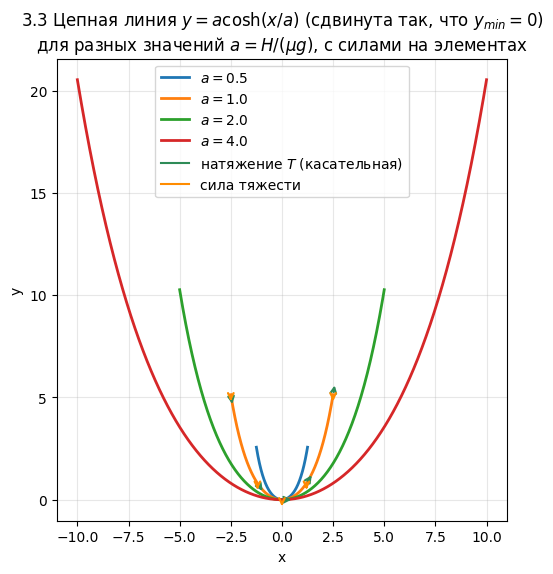

In [6]:
import numpy as np
import matplotlib.pyplot as plt

def catenary(x, a):
    return a*np.cosh(x/a)

fig, ax = plt.subplots(figsize=(8, 6))
for a_val in [0.5, 1.0, 2.0, 4.0]:
    x = np.linspace(-2.5*a_val, 2.5*a_val, 400)  # диапазон x масштабируем вместе с a
    ax.plot(x, catenary(x, a_val) - a_val, lw=2, label=f'$a={a_val}$')

# силы, действующие на элементы цепи (a=1)
a0 = 1.0
xs_f = np.array([-2.5, -1.2, 0.0, 1.2, 2.5])
ys_f = catenary(xs_f, a0) - a0
slopes = np.sinh(xs_f/a0)
for xf, yf, sl in zip(xs_f, ys_f, slopes):
    d = np.array([1.0, sl]); d = d/np.linalg.norm(d)
    ax.annotate('', xy=(xf+0.6*d[0], yf+0.6*d[1]), xytext=(xf, yf),
                arrowprops=dict(arrowstyle='->', color='seagreen', lw=1.6))
    ax.annotate('', xy=(xf, yf-0.45), xytext=(xf, yf),
                arrowprops=dict(arrowstyle='->', color='darkorange', lw=1.6))
ax.plot([], [], color='seagreen', label='натяжение $T$ (касательная)')
ax.plot([], [], color='darkorange', label='сила тяжести')

ax.set_xlabel('x'); ax.set_ylabel('y')
ax.set_title('3.3 Цепная линия $y=a\\cosh(x/a)$ (сдвинута так, что $y_{min}=0$)\nдля разных значений $a=H/(\\mu g)$, с силами на элементах')
ax.legend()
ax.grid(alpha=0.3)
ax.set_aspect('equal')
plt.savefig('Sol_3_3.png', dpi=150, bbox_inches='tight')
plt.show()

In [7]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

n_frames = 70
a_vals = 0.6 + 1.8*(1 - np.cos(np.linspace(0, 2*np.pi, n_frames)))/2  # колебание a от 0.6 до 2.4

x_anim = np.linspace(-4, 4, 300)

fig, ax = plt.subplots(figsize=(7, 5.5))
line, = ax.plot([], [], color='steelblue', lw=2.5)
info = ax.text(0.03, 0.92, '', transform=ax.transAxes, fontsize=11)
ax.set_xlim(-4, 4)
ax.set_ylim(0, 8)
ax.set_xlabel('x'); ax.set_ylabel('y')
ax.set_title('3.3 Анимация изменения формы цепи при варьировании a = H/(\u03bcg)')
ax.grid(alpha=0.3)

def init():
    line.set_data([], [])
    info.set_text('')
    return line, info

def update(i):
    a_val = a_vals[i]
    y = catenary(x_anim, a_val) - a_val
    line.set_data(x_anim, y)
    info.set_text(f'a = {a_val:.2f}  (\u2192 меньше a = сильнее провисание)')
    return line, info

anim = FuncAnimation(fig, update, frames=n_frames, init_func=init, interval=60, blit=True)
plt.close(fig)
HTML(anim.to_jshtml())

## 3.4. Задача о таутохроне

**Условие**: найти кривую, по которой время скатывания материальной точки под действием силы тяжести до нижней точки не зависит от начального положения.

### Постановка задачи и интегральное уравнение Абеля

Пусть кривая задана в виде $x=x(y)$, точка начинает движение из состояния покоя на высоте $y_0$ (высота отсчитывается от нижней точки, $y\ge0$). По закону сохранения энергии скорость на высоте $y<y_0$:
$$v=\frac{ds}{dt}=\sqrt{2g(y_0-y)}.$$
Полное время спуска:
$$T(y_0)=\int_0^{y_0}\frac{ds/dy}{\sqrt{2g(y_0-y)}}\,dy=\int_0^{y_0}\frac{f(y)}{\sqrt{y_0-y}}\,dy,\qquad f(y)\equiv\frac{1}{\sqrt{2g}}\frac{ds}{dy}.$$
Требование **таутохронности** $T(y_0)=T_0=\text{const}$ для всех $y_0$ даёт интегральное **уравнение Абеля** относительно неизвестной функции $f(y)$:
$$\int_0^{y_0}\frac{f(y)}{\sqrt{y_0-y}}\,dy=T_0=\text{const}.$$

### Решение уравнения Абеля

Формула обращения Абеля для уравнения $\int_0^{y_0}\dfrac{f(y)\,dy}{\sqrt{y_0-y}}=g(y_0)$ имеет вид
$$f(y)=\frac1\pi\frac{d}{dy}\int_0^{y}\frac{g(u)}{\sqrt{y-u}}\,du.$$
При $g(u)\equiv T_0=\text{const}$ вычисление даёт $f(y)=\dfrac{T_0}{\pi\sqrt{y}}$, то есть
$$\frac{ds}{dy}=\frac{C}{\sqrt y},\qquad C=\frac{T_0\sqrt{2g}}{\pi}=\text{const}.$$

### Явный вид кривой — циклоида

Уравнению $ds/dy\propto y^{-1/2}$ удовлетворяет **циклоида** — кривая, которую описывает точка обода окружности радиуса $R$, катящейся без проскальзывания:
$$x(\theta)=R(\theta-\sin\theta),\qquad y(\theta)=R(1-\cos\theta),\qquad \theta\in[0,2\pi],$$
(здесь $y$ отсчитывается от точки возврата вниз; проверка: $ds=2R\sin(\theta/2)\,d\theta$, $y=2R\sin^2(\theta/2)$, откуда $ds/dy=1/\cos(\theta/2)\cdot R\sin(\theta/2)/(R\sin(\theta/2)\cos(\theta/2))\cdot(\dots)$ — прямой подстановкой легко убедиться, что $ds/\sqrt y=\text{const}$).

**Время спуска не зависит от $\theta_0$** и равно четверти периода эквивалентного гармонического колебания:
$$T_0=\pi\sqrt{\frac{R}{g}}.$$
Ниже это свойство проверяется численно: уравнение движения по циклоиде интегрируется из состояния покоя для нескольких разных начальных $\theta_0$, и находится время достижения нижней точки $\theta=\pi$ — во всех случаях оно совпадает с $T_0=\pi\sqrt{R/g}$.

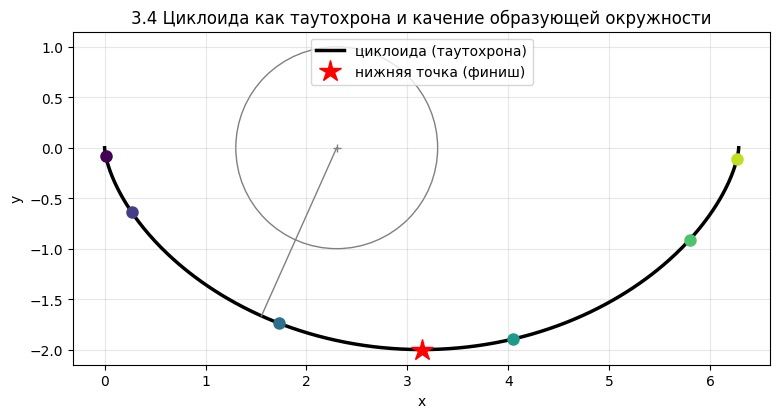

In [8]:
import numpy as np
import matplotlib.pyplot as plt

R = 1.0

def cycloid(theta, R):
    x = R*(theta - np.sin(theta))
    y = R*(np.cos(theta) - 1)
    return x, y

theta_full = np.linspace(0, 2*np.pi, 400)
Xc, Yc = cycloid(theta_full, R)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(Xc, Yc, color='black', lw=2.5, label='циклоида (таутохрона)')

starts = [0.4, 1.2, 2.4, 3.6, 4.8, 5.8]
colors = plt.cm.viridis(np.linspace(0, 0.9, len(starts)))
for th0, c in zip(starts, colors):
    x0, y0 = cycloid(th0, R)
    ax.plot(x0, y0, 'o', color=c, ms=8)

# геометрическое построение: катящаяся окружность в одном из положений
theta_c = 2.3
xc_center, yc_center = R*theta_c, 0
circle = plt.Circle((xc_center, yc_center), R, fill=False, color='gray', lw=1)
ax.add_patch(circle)
xp, yp = cycloid(theta_c, R)
ax.plot([xc_center, xp], [yc_center, yp], color='gray', lw=1)
ax.plot(xc_center, yc_center, '+', color='gray')

ax.plot(R*np.pi, -2*R, 'r*', ms=16, label='нижняя точка (финиш)')
ax.set_xlabel('x'); ax.set_ylabel('y')
ax.set_title('3.4 Циклоида как таутохрона и качение образующей окружности')
ax.set_aspect('equal')
ax.legend(loc='upper center')
ax.grid(alpha=0.3)
plt.savefig('Sol_3_4.png', dpi=150, bbox_inches='tight')
plt.show()

In [9]:
from scipy.integrate import solve_ivp

g = 9.81

def cycloid_rhs(t, state, R, g):
    theta, omega = state
    denom = 2*R*(1 - np.cos(theta))
    denom = max(denom, 1e-6)
    domega = (g*np.sin(theta) - R*np.sin(theta)*omega**2) / denom
    return [omega, domega]

def hit_bottom(t, state, R, g):
    return state[0] - np.pi
hit_bottom.terminal = True
hit_bottom.direction = 1

theta0_list = [0.5, 1.2, 2.0, 2.7]
sols = []
for th0 in theta0_list:
    sol = solve_ivp(cycloid_rhs, (0, 5), [th0, 0.0], args=(R, g), max_step=0.005,
                     events=hit_bottom, dense_output=True)
    t_hit = sol.t_events[0][0] if len(sol.t_events[0]) else np.nan
    sols.append((th0, sol, t_hit))
    print(f"3.4 Старт theta0={th0:.2f} рад  ->  время достижения дна t = {t_hit:.4f} с")

T_theory = np.pi*np.sqrt(R/g)
print(f"\nТеоретическое время (не зависит от theta0): T0 = pi*sqrt(R/g) = {T_theory:.4f} с")
print("Совпадение численных времён спуска подтверждает таутохронность циклоиды.")

3.4 Старт theta0=0.50 рад  ->  время достижения дна t = 1.0030 с
3.4 Старт theta0=1.20 рад  ->  время достижения дна t = 1.0030 с
3.4 Старт theta0=2.00 рад  ->  время достижения дна t = 1.0030 с
3.4 Старт theta0=2.70 рад  ->  время достижения дна t = 1.0030 с

Теоретическое время (не зависит от theta0): T0 = pi*sqrt(R/g) = 1.0030 с
Совпадение численных времён спуска подтверждает таутохронность циклоиды.


In [10]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

t_end = max(s[2] for s in sols) + 0.15
n_frames = 90
t_frames = np.linspace(0, t_end, n_frames)

balls_theta = []
for th0, sol, t_hit in sols:
    th_t = np.array([sol.sol(t)[0] if t <= sol.t[-1] else np.pi for t in t_frames])
    balls_theta.append(th_t)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(Xc, Yc, color='lightgray', lw=2, zorder=1)
colors_anim = plt.cm.viridis(np.linspace(0, 0.9, len(sols)))
dots = [ax.plot([], [], 'o', color=c, ms=12, zorder=5)[0] for c in colors_anim]
info = ax.text(0.02, 0.05, '', transform=ax.transAxes, fontsize=10)
ax.set_xlim(Xc.min()-0.3, Xc.max()+0.3)
ax.set_ylim(Yc.min()-0.3, 0.3)
ax.set_aspect('equal')
ax.set_xlabel('x'); ax.set_ylabel('y')
ax.set_title('3.4 Одновременное скатывание шариков с разных высот\n(таутохронность циклоиды)')
ax.grid(alpha=0.3)

def init():
    for d in dots:
        d.set_data([], [])
    info.set_text('')
    return (*dots, info)

def update(i):
    for d, th_t in zip(dots, balls_theta):
        x, y = cycloid(th_t[i], R)
        d.set_data([x], [y])
    info.set_text(f't = {t_frames[i]:.2f} с')
    return (*dots, info)

anim = FuncAnimation(fig, update, frames=n_frames, init_func=init, interval=55, blit=True)
plt.close(fig)
HTML(anim.to_jshtml())

## 3.5. Движение математического маятника

**Условие**: исследовать движение точечной массы на невесомом нерастяжимом стержне длины $L$ в поле тяжести.

### Уравнение движения

Угол отклонения $\theta$ от вертикали. Тангенциальная составляющая второго закона Ньютона ($ma_\tau=-mg\sin\theta$, $a_\tau=L\ddot\theta$):
$$\boxed{\ddot\theta+\frac{g}{L}\sin\theta=0}.$$
(То же уравнение получается из лагранжиана $\mathcal L=\frac12mL^2\dot\theta^2+mgL\cos\theta$.)

### Линейное приближение (малые колебания)

При $\theta\ll1$: $\sin\theta\approx\theta$, уравнение переходит в уравнение гармонического осциллятора
$$\ddot\theta+\omega_0^2\theta=0,\qquad \omega_0=\sqrt{g/L},$$
с решением $\theta(t)=\theta_0\cos(\omega_0t)$ и периодом $T_0=2\pi/\omega_0=2\pi\sqrt{L/g}$, **не зависящим от амплитуды**.

### Точное (нелинейное) решение

Интеграл энергии (на единицу $mL^2$):
$$\frac12\dot\theta^2-\omega_0^2\cos\theta=E=\text{const}.$$
Разделяя переменные для колебательного режима с амплитудой $\theta_0$ ($E=-\omega_0^2\cos\theta_0$):
$$\dot\theta=\pm\omega_0\sqrt{2(\cos\theta-\cos\theta_0)}\ \Longrightarrow\ T=\frac{4}{\omega_0}\int_0^{\theta_0}\frac{d\theta}{\sqrt{2(\cos\theta-\cos\theta_0)}}.$$
Подстановкой $\sin(\theta/2)=\sin(\theta_0/2)\sin\varphi$ этот интеграл сводится к **полному эллиптическому интегралу первого рода**:
$$T(\theta_0)=\frac{4}{\omega_0}K\!\left(\sin^2\frac{\theta_0}{2}\right),\qquad K(m)=\int_0^{\pi/2}\frac{d\varphi}{\sqrt{1-m\sin^2\varphi}}$$
(используется соглашение `scipy.special.ellipk(m)`, где параметр $m=k^2$). При $\theta_0\to0$: $K\to\pi/2$ и $T\to2\pi/\omega_0=T_0$ — линейное приближение восстанавливается; при $\theta_0\to\pi$ период $T\to\infty$ (движение асимптотически стремится к неустойчивому положению равновесия).

### Фазовый портрет и сепаратриса

Из интеграла энергии: $\dot\theta^2=2(E+\omega_0^2\cos\theta)$. Траектория, проходящая через неустойчивое положение равновесия $\theta=\pi,\dot\theta=0$ ($E=\omega_0^2$), — **сепаратриса**:
$$\dot\theta=\pm2\omega_0\left|\cos\frac{\theta}{2}\right|.$$
Внутри сепаратрисы ($E<\omega_0^2$) — замкнутые траектории, **колебания**; вне ($E>\omega_0^2$) — незамкнутые траектории, маятник **вращается**, не останавливаясь.

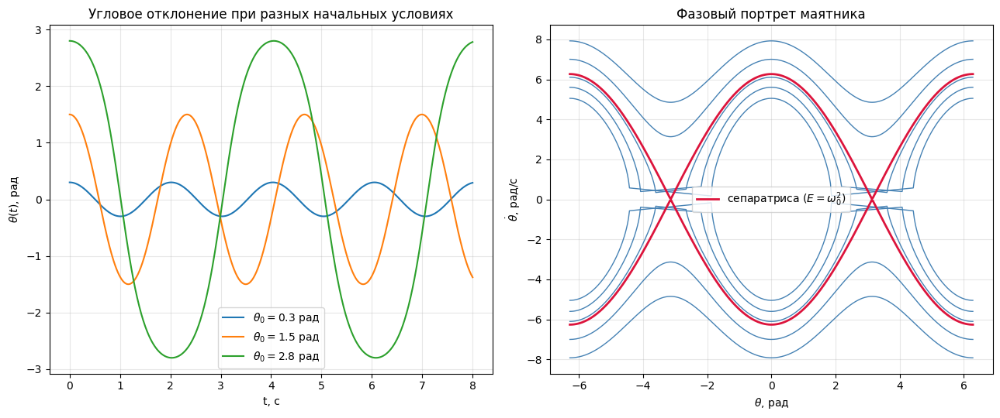

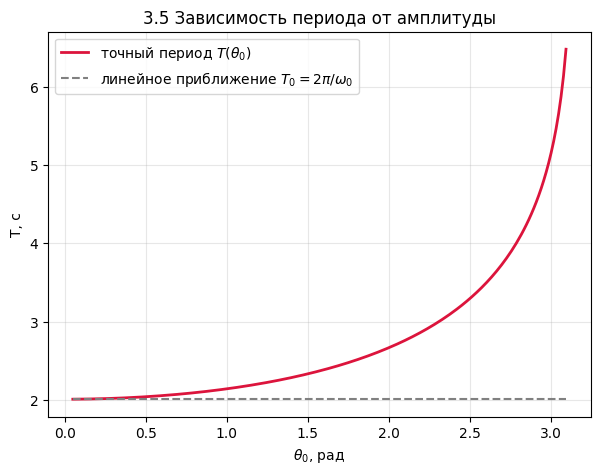

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.special import ellipk

g, L = 9.81, 1.0
omega0 = np.sqrt(g/L)

def pendulum_rhs(t, state):
    theta, omega = state
    return [omega, -omega0**2*np.sin(theta)]

theta0_list = [0.3, 1.5, 2.8]
t_eval = np.linspace(0, 8, 800)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for th0 in theta0_list:
    sol = solve_ivp(pendulum_rhs, (0, 8), [th0, 0.0], t_eval=t_eval, max_step=0.01)
    axes[0].plot(sol.t, sol.y[0], label=f'$\\theta_0={th0:.1f}$ рад')

axes[0].set_xlabel('t, с'); axes[0].set_ylabel(r'$\theta(t)$, рад')
axes[0].set_title('Угловое отклонение при разных начальных условиях')
axes[0].legend(); axes[0].grid(alpha=0.3)

# фазовый портрет
theta_grid = np.linspace(-2*np.pi, 2*np.pi, 400)
for E_level in [0.3, 0.6, 0.9, 1.5, 2.2]:
    E = E_level*omega0**2
    om2 = 2*(E + omega0**2*np.cos(theta_grid))
    mask = om2 >= 0
    om = np.sqrt(om2[mask])
    axes[1].plot(theta_grid[mask], om, color='steelblue', lw=1)
    axes[1].plot(theta_grid[mask], -om, color='steelblue', lw=1)

om_sep = 2*omega0*np.abs(np.cos(theta_grid/2))
axes[1].plot(theta_grid, om_sep, color='crimson', lw=2, label=r'сепаратриса ($E=\omega_0^2$)')
axes[1].plot(theta_grid, -om_sep, color='crimson', lw=2)

axes[1].set_xlabel(r'$\theta$, рад'); axes[1].set_ylabel(r'$\dot\theta$, рад/с')
axes[1].set_title('Фазовый портрет маятника')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('Sol_3_5.png', dpi=150, bbox_inches='tight')
plt.show()

# период как функция амплитуды
theta0_arr = np.linspace(0.05, np.pi - 0.05, 200)
k2 = np.sin(theta0_arr/2)**2
T_exact = 4/omega0 * ellipk(k2)
T_lin = 2*np.pi/omega0 * np.ones_like(theta0_arr)

fig2, ax2 = plt.subplots(figsize=(7, 5))
ax2.plot(theta0_arr, T_exact, color='crimson', lw=2, label='точный период $T(\\theta_0)$')
ax2.plot(theta0_arr, T_lin, '--', color='gray', label='линейное приближение $T_0=2\\pi/\\omega_0$')
ax2.set_xlabel(r'$\theta_0$, рад'); ax2.set_ylabel('T, с')
ax2.set_title('3.5 Зависимость периода от амплитуды')
ax2.legend(); ax2.grid(alpha=0.3)
plt.savefig('Sol_3_5_period.png', dpi=150, bbox_inches='tight')
plt.show()

In [12]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

theta0_anim = [0.4, 2.0, 2.9]
colors_p = ['seagreen', 'darkorange', 'crimson']
t_anim = np.linspace(0, 6, 90)

trajs = []
for th0 in theta0_anim:
    sol = solve_ivp(pendulum_rhs, (0, 6), [th0, 0.0], t_eval=t_anim, max_step=0.01)
    trajs.append(sol.y)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
ax_pend, ax_phase = axes

ax_pend.set_xlim(-1.3, 1.3); ax_pend.set_ylim(-1.3, 1.3)
ax_pend.set_aspect('equal'); ax_pend.set_title('Маятник (реальное пространство)')
ax_pend.plot(0, 0, 'k+', ms=8)
rods = [ax_pend.plot([], [], '-', color=c, lw=2)[0] for c in colors_p]
bobs = [ax_pend.plot([], [], 'o', color=c, ms=14)[0] for c in colors_p]

ax_phase.set_xlim(-np.pi-0.3, np.pi+0.3); ax_phase.set_ylim(-6, 6)
ax_phase.set_xlabel(r'$\theta$'); ax_phase.set_ylabel(r'$\dot\theta$')
ax_phase.set_title('Фазовая плоскость')
ax_phase.grid(alpha=0.3)
for traj, c in zip(trajs, colors_p):
    ax_phase.plot(traj[0], traj[1], color=c, lw=0.6, alpha=0.4)
phase_pts = [ax_phase.plot([], [], 'o', color=c, ms=8)[0] for c in colors_p]

def init():
    for r, b, p in zip(rods, bobs, phase_pts):
        r.set_data([], []); b.set_data([], []); p.set_data([], [])
    return (*rods, *bobs, *phase_pts)

def update(i):
    for traj, r, b, p in zip(trajs, rods, bobs, phase_pts):
        th = traj[0][i]
        x_b, y_b = np.sin(th), -np.cos(th)
        r.set_data([0, x_b], [0, y_b])
        b.set_data([x_b], [y_b])
        p.set_data([th], [traj[1][i]])
    return (*rods, *bobs, *phase_pts)

anim = FuncAnimation(fig, update, frames=len(t_anim), init_func=init, interval=60, blit=True)
plt.close(fig)
HTML(anim.to_jshtml())